In [5]:
pip install google-play-scraper scikit-learn imbalanced-learn Sastrawi wordcloud seaborn matplotlib pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
from google_play_scraper import Sort, reviews
from IPython.display import display
import pandas as pd
import numpy as np

# Step 1: Scraping ulasan aplikasi Ruangguru
result, continuation_token = reviews(
    'com.ruangguru.livestudents',  # Package name aplikasi Ruangguru
    lang='id',                     # Bahasa Indonesia
    country='id',                  # Negara Indonesia
    sort=Sort.MOST_RELEVANT,       # Ulasan paling relevan
    count=1000,                    # Jumlah ulasan yang diambil
    filter_score_with=None         # Semua rating
)

# Step 2: Mengubah hasil scraping menjadi DataFrame
df_reviews = pd.DataFrame(np.array(result), columns=['review'])
df_reviews = df_reviews.join(
    pd.DataFrame(df_reviews.pop('review').tolist())
)

# Step 3: Memilih kolom yang relevan
new_df = df_reviews[['userName', 'score', 'at', 'content']]

# Step 4: Mengurutkan ulasan berdasarkan tanggal terbaru
sorted_df = new_df.sort_values(
    by='at',
    ascending=False
)

# Step 5: Menyimpan data ke CSV
my_df = sorted_df[['userName', 'score', 'at', 'content']]
my_df.to_csv(
   "ulasan_ruangguru.csv",
    index=False
)

# Step 6: Menampilkan hasil
print("Jumlah ulasan:", len(my_df))
print("Data berhasil disimpan ke file CSV.")
my_df.head()

Jumlah ulasan: 1000
Data berhasil disimpan ke file CSV.


,userName,score,at,content
33,Kenosis Miracle yani,5,2026-10-19 09:04:59,aplikasinya sangat interaktif dan membantu say...
92,Nurafni Lala,5,2026-10-17 16:36:49,bagus dan bisa memperlancar anak pintar dan be...
43,Top up robux,5,2026-10-17 16:23:56,the best bagus bener dan juga mudah untuk nger...
35,Rokayah,5,2026-10-16 21:14:38,"belajar jadi lebih mudah,asik,seru dan menyena..."
34,Altaf,5,2026-10-16 12:44:16,ruangguru mantap banget gratis pasti. aku dapa...


In [7]:
import re, json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Negatif": "#EF4444", "Netral": "#F59E0B", "Positif": "#10B981"}
SEED = 42

In [8]:
SCRAPE = False
DATA_PATH = "ulasan_ruangguru.csv"
APP_ID ="com.ruangguru.livestudents"
N_REVIEWS = 1000

if SCRAPE :
    from google_play_scraper import Sort, reviews
    result, _ = reviews(APP_ID, lang="id", country="id", sort=Sort.MOST_RELEVANT, count=N_REVIEWS)
    df_raw = pd.DataFrame(result)[["Username", "score", "at", "content"]]
    df_raw = df_raw.sort_values("at", ascending=False)
    df_raw.to_csv(DATA_PATH, index=False)
else:
    df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
 
# Validasi kolom & buang data kosong
assert {"score", "content"}.issubset(df_raw.columns), "Kolom 'score' dan 'content' wajib ada"
df = df_raw.dropna(subset=["content", "score"]).copy()
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df = df.reset_index(drop=True)
print(f"Data dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Data dimuat: 1000 baris, 4 kolom


,userName,score,at,content
0,Kenosis Miracle yani,5,2026-10-19 09:04:59,aplikasinya sangat interaktif dan membantu say...
1,Nurafni Lala,5,2026-10-17 16:36:49,bagus dan bisa memperlancar anak pintar dan be...
2,Top up robux,5,2026-10-17 16:23:56,the best bagus bener dan juga mudah untuk nger...
3,Rokayah,5,2026-10-16 21:14:38,"belajar jadi lebih mudah,asik,seru dan menyena..."
4,Altaf,5,2026-10-16 12:44:16,ruangguru mantap banget gratis pasti. aku dapa...


In [9]:
# %% 2. Eksplorasi Data (EDA)
print(df.info())
print("\nMissing value:\n", df.isna().sum())
print(f"\nRentang tanggal: {df['at'].min():%d %b %Y} → {df['at'].max():%d %b %Y}")
print(f"Ulasan duplikat: {df.duplicated(subset='content').sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   userName  1000 non-null   str           
 1   score     1000 non-null   int64         
 2   at        1000 non-null   datetime64[us]
 3   content   1000 non-null   str           
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 347.6 KB
None

Missing value:
 userName    0
score       0
at          0
content     0
dtype: int64

Rentang tanggal: 15 Sep 2018 → 19 Oct 2026
Ulasan duplikat: 2


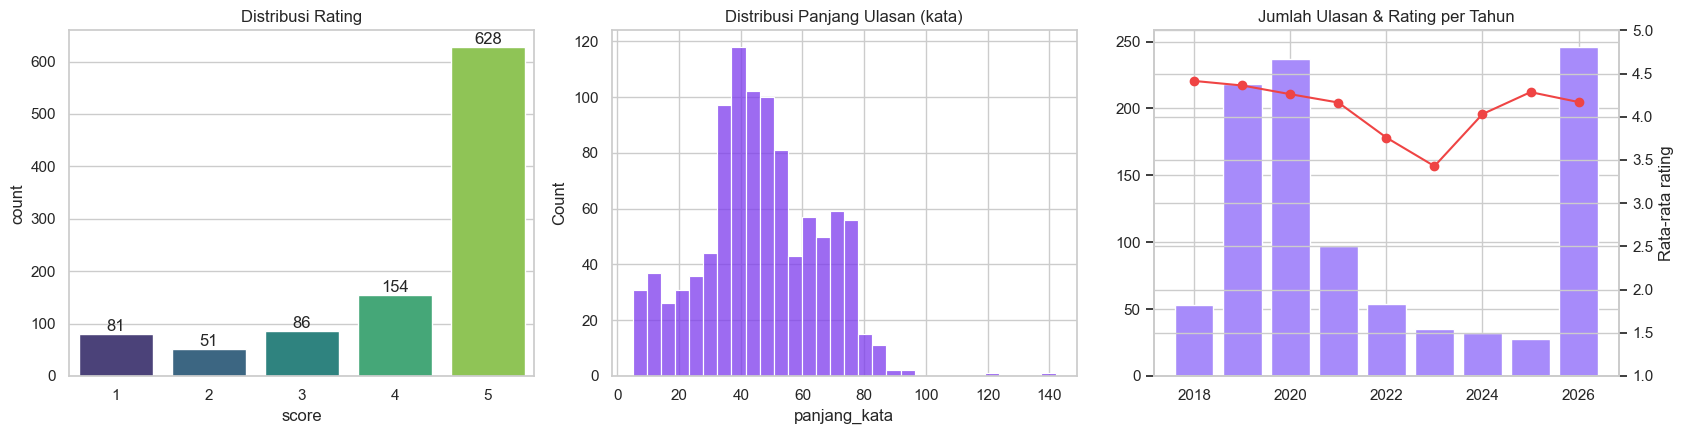

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
 
sns.countplot(data=df, x="score", palette="viridis", ax=ax[0])
ax[0].set_title("Distribusi Rating")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
 
df["panjang_kata"] = df["content"].astype(str).str.split().str.len()
sns.histplot(df["panjang_kata"], bins=30, color="#7C3AED", ax=ax[1])
ax[1].set_title("Distribusi Panjang Ulasan (kata)")
 
yr = df.dropna(subset=["at"]).groupby(df["at"].dt.year).agg(jumlah=("score", "size"), rating=("score", "mean"))
ax[2].bar(yr.index, yr["jumlah"], color="#A78BFA")
# CATATAN: teks set_ylabel terpotong di foto ("Rata-rata rat..."), dilengkapi dengan tebakan
ax2 = ax[2].twinx(); ax2.plot(yr.index, yr["rating"], color="#EF4444", marker="o"); ax2.set_ylim(1, 5); ax2.set_ylabel("Rata-rata rating")
ax[2].set_title("Jumlah Ulasan & Rating per Tahun")
plt.tight_layout(); plt.show()

label
Positif    782
Negatif    132
Netral      86
Name: count, dtype: int64
label
Positif    78.2 %
Negatif    13.2 %
Netral      8.6 %
Name: count, dtype: str


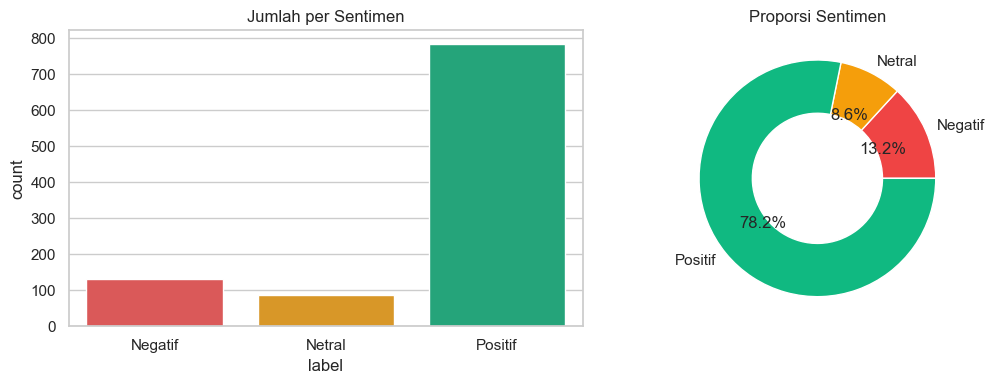

In [11]:
# %% Pelabelan sentimen berdasarkan rating
def beri_label(score):
    if score <= 2: return "Negatif"
    if score == 3: return "Netral"
    return "Positif"
 
df["label"] = df["score"].apply(beri_label)
dist = df["label"].value_counts()
print(dist)
print((dist / dist.sum() * 100).round(1).astype(str) + " %")
 
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ["Negatif", "Netral", "Positif"]
sns.countplot(data=df, x="label", order=order, palette=PALETTE, ax=ax[0]); ax[0].set_title("Jumlah per Sentimen")
ax[1].pie(dist[order], labels=order, autopct="%1.1f%%", colors=[PALETTE[o] for o in order], wedgeprops=dict(width=.45))
ax[1].set_title("Proporsi Sentimen"); plt.tight_layout(); plt.show()

In [12]:
STOPWORDS = {
    "di","dari","ke","pada","dengan","untuk","oleh","tentang","kepada","yang","dan","atau","tetapi","tapi",
    "karena","meskipun","jika","agar","saya","aku","kamu","dia","kita","mereka","ini","itu","lah","tuh","nya",
    "dong","aja","gitu","deh","emang","ya","sih","kok","lho","nih","si","pun","juga","sudah","akan","lagi",
    "pernah","hanya","adalah","dalam","ada","para","sebagai","saat","ketika","kalau","kalo","jadi","sama","mau",
}
NEGATIONS = {"tidak","bukan","belum","jangan","kurang","gak","ga","nggak","ngga","tak","gk","enggak"}
DOMAIN_STOPWORDS = {"ruangguru", "rg", "ruang", "kak"}   # nama aplikasi: muncul di hampir semua ulasan

SLANG = {
    "gak":"tidak","ga":"tidak","nggak":"tidak","ngga":"tidak","gk":"tidak","enggak":"tidak","tdk":"tidak","tak":"tidak",
    "bgt":"banget","bgus":"bagus","bagu":"bagus","bagust":"bagus","mantul":"mantap","udh":"sudah","udah":"sudah",
    "sdh":"sudah","blm":"belum","yg":"yang","dgn":"dengan","krn":"karena","karna":"karena","utk":"untuk","jd":"jadi",
    "tp":"tapi","tpi":"tapi","klo":"kalau","kalo":"kalau","sy":"saya","sm":"sama","sma":"sama","bs":"bisa","bsa":"bisa",
    "gabisa":"tidak bisa","lemot":"lambat","lag":"lambat","ngelag":"lambat","eror":"error","erorr":"error",
    "apk":"aplikasi","app":"aplikasi","aplikasinya":"aplikasi","thx":"terima kasih","makasih":"terima kasih",
    "terimakasih":"terima kasih","trims":"terima kasih","oke":"ok","okey":"ok","recomended":"recommended",
    "rekomen":"recommended","kereen":"keren","jelek":"buruk","jlek":"buruk","pake":"pakai","pke":"pakai",
    "jg":"juga","dr":"dari","dl":"dulu","bgmn":"bagaimana","gmn":"bagaimana","knp":"kenapa","kyk":"seperti",
    "bnyk":"banyak","bebrpa":"beberapa",
}

# --- Stemmer Sastrawi (lambat, jadi hasil per-kata disimpan di cache) ---
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
stemmer = StemmerFactory().create_stemmer()
STEM_CACHE_FILE = "stem_cache.json"
stem_cache = json.load(open(STEM_CACHE_FILE, encoding="utf-8")) if os.path.exists(STEM_CACHE_FILE) else {}
 
def stem_kata(w):
    if w not in stem_cache:
        stem_cache[w] = stemmer.stem(w)
    return stem_cache[w]
 
def bersihkan_teks(teks, stemming=True, hapus_stopword=True):
    t = str(teks).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)              # URL
    t = re.sub(r"\bruang\s+guru\b", "ruangguru", t)      # satukan nama aplikasi
    t = re.sub(r"(.)\1{2,}", r"\1", t)                   # bagusssss -> bagus
    t = re.sub(r"[^a-z\s]", " ", t)                      # angka, simbol, emoji
    tokens = " ".join(SLANG.get(w, w) for w in t.split()).split()
    if hapus_stopword:
        tokens = [w for w in tokens if (w not in STOPWORDS or w in NEGATIONS) and w not in DOMAIN_STOPWORDS]
    tokens = [w for w in tokens if len(w) > 1]
    if stemming:
        # CATATAN: isi di bawah ini tidak terlihat di foto, ini TEBAKAN; sesuaikan dengan notebook asli
        tokens = [stem_kata(w) for w in tokens]
    return " ".join(tokens)

contoh = "Aplikasinya bgt membantuuuu! tpi kadang lemot $ gak bisa login https://x.id"
print("Asli :", contoh)
print("Bersih:", bersihkan_teks(contoh))

Asli : Aplikasinya bgt membantuuuu! tpi kadang lemot $ gak bisa login https://x.id
Bersih: aplikasi banget bantu kadang lambat tidak bisa login


In [13]:
df["clean_content"] = df["content"].apply(bersihkan_teks)
json.dump(stem_cache, open(STEM_CACHE_FILE, "w", encoding="utf-8"), ensure_ascii=False)
 
# Buang ulasan yang kosong setelah dibersihkan
n0 = len(df)
df = df[df["clean_content"].str.strip().str.len() > 0].reset_index(drop=True)
df["jumlah_kata"] = df["clean_content"].str.split().str.len()
print(f"Data setelah preprocessing: {len(df)} (dibuang {n0-len(df)})")
df[["content", "clean_content", "label"]].sample(8, random_state=3)

Data setelah preprocessing: 999 (dibuang 1)


,content,clean_content,label
642,Belajarku jadi efisien dan efektif untuk utbk ...,ajar efisien efektif utbk terima kasih akhir s...,Positif
761,"Bagus banget, gara"" ruang guru nilai fisika ak...",bagus banget gara nilai fisika naik awal bisa ...,Positif
908,"kerenn sih aplikasi ini:)) tutornya asik, vide...",kerenn aplikasi tutor asik video mudah erti an...,Positif
199,"keren, belajar jadi gampang karena adanya visu...",keren ajar gampang ada visualisasi mudah paham...,Positif
586,Saya sarankan untuk rekamannya agar lebih dipe...,saran rekam lebih perhati kemarin beli paket k...,Negatif
796,"Aplikasi bagus, sangat membantu kami yang seda...",aplikasi bagus sangat bantu kami sedang juang ...,Positif
652,Suka Ruanhguru karena materinya nyaman untuk d...,suka ruanhguru materi nyaman paham video beran...,Positif
901,saya suka belajar diruang guru dan juga mudah ...,suka ajar ruang guru mudah banget erti perlu t...,Positif


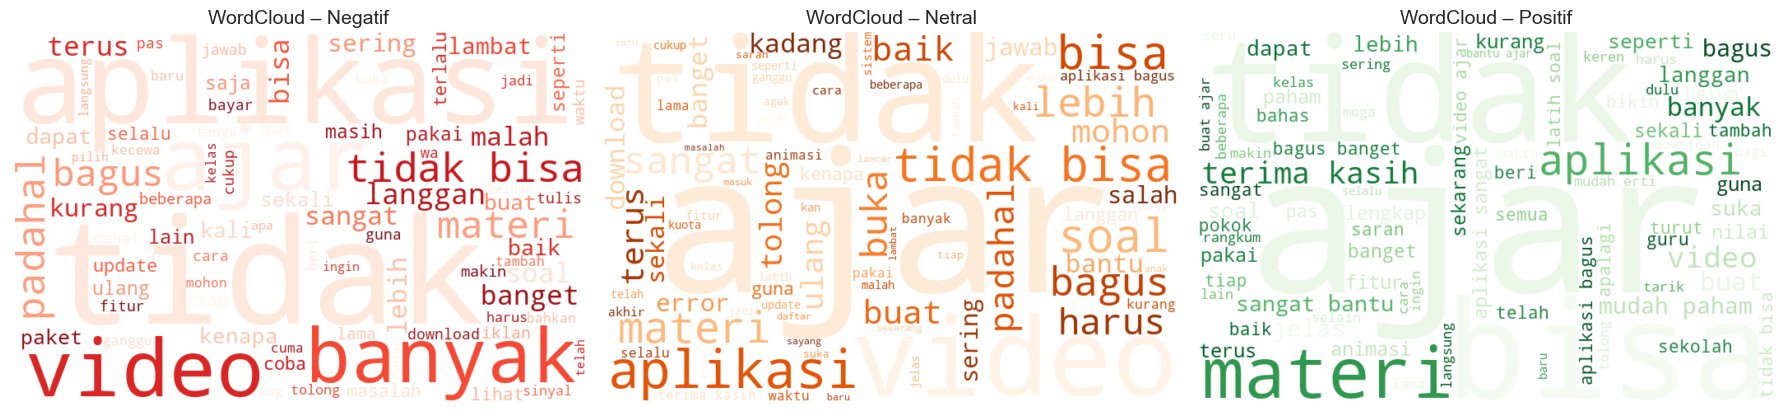

In [14]:
# %% 4.1 Visualisasi WordCloud & Kata Teratas per Sentimen
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    teks = " ".join(df.loc[df["label"] == lab, "clean_content"])
    # CATATAN: ujung baris colormap terpotong di foto ("... if lab==\"Netral\" el"); "Greens" adalah TEBAKAN
    wc = WordCloud(width=700, height=450, background_color="white", colormap="Reds" if lab=="Negatif" else "Oranges" if lab=="Netral" else "Greens",
                   max_words=80, random_state=SEED).generate(teks)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"WordCloud – {lab}", fontsize=14)
plt.tight_layout(); plt.show()

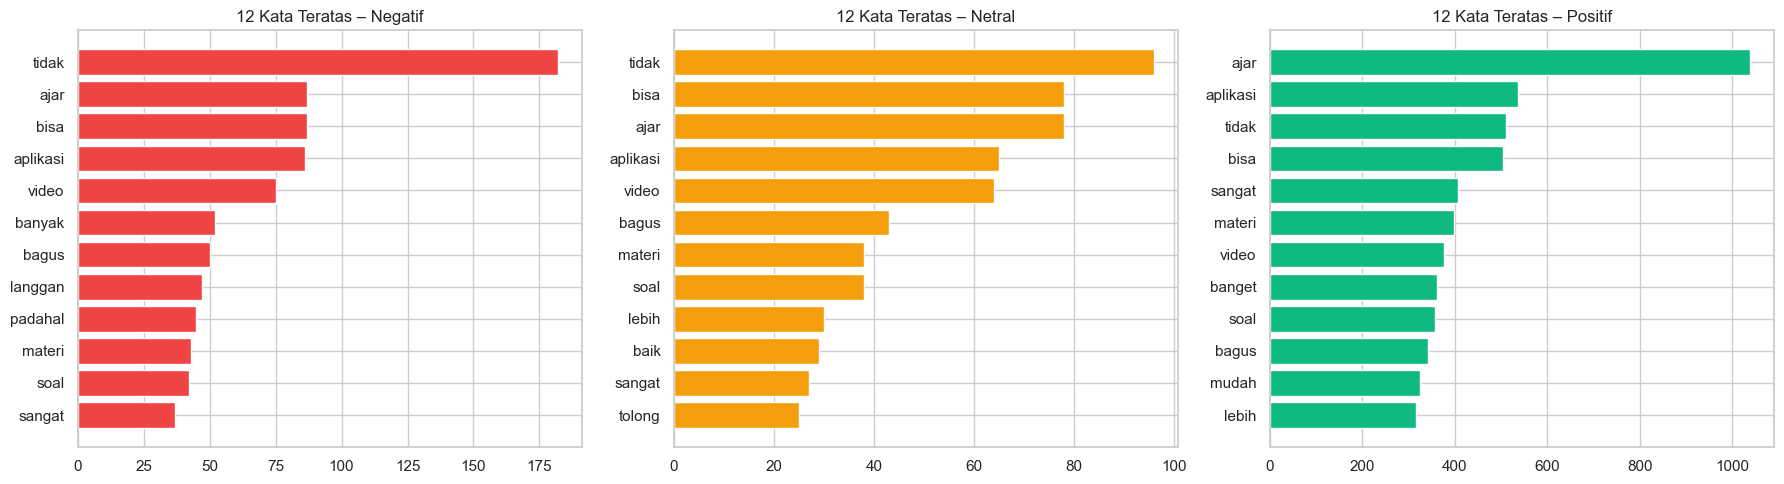

In [15]:
# %% Kata teratas per sentimen
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    top = pd.Series(" ".join(df.loc[df["label"] == lab, "clean_content"]).split()).value_counts().head(12)[::-1]
    ax.barh(top.index, top.values, color=PALETTE[lab]); ax.set_title(f"12 Kata Teratas – {lab}")
plt.tight_layout(); plt.show()

In [16]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean_content"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED
)

print(f"Data latih: {len(X_train_txt)} | Data uji: {len(X_test_txt)}")
pd.DataFrame({"Latih": y_train.value_counts(), "Uji": y_test.value_counts()})

Data latih: 799 | Data uji: 200


,Latih,Uji
label,,
Positif,625,156
Negatif,105,27
Netral,69,17


In [17]:
def buat_sampler(y, faktor=1.0):
    min_n = int(pd.Series(y).value_counts().min() * faktor)
    k = min(5, min_n - 1)
    return SMOTE(k_neighbors=k, random_state=SEED) if k >= 1 else RandomOverSampler(random_state=SEED)

N_FOLD = 5

pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB()),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [2000, 5000],
    "tfidf__min_df": [1, 2, 3],
    "nb__alpha": [0.05, 0.1, 0.3, 0.5, 1.0],
}

gs = GridSearchCV(pipe, param_grid, scoring="f1_macro",
                  cv=StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED), n_jobs=-1)
gs.fit(X_train_txt, y_train)

print("Parameter terbaik:", gs.best_params_)
print(f"F1-macro CV terbaik: {gs.best_score_:.4f}")
hasil_grid = (pd.DataFrame(gs.cv_results_)[["mean_test_score", "param_tfidf__ngram_range","param_tfidf__max_features","param_tfidf__min_df","param_nb__alpha"]]
              .rename(columns=lambda c: c.replace("param_", "")).sort_values("mean_test_score", ascending=False))
hasil_grid.head(10)

Parameter terbaik: {'nb__alpha': 1.0, 'tfidf__max_features': 2000, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}
F1-macro CV terbaik: 0.5797


,mean_test_score,tfidf__ngram_range,tfidf__max_features,tfidf__min_df,nb__alpha
58,0.579693,"(1, 1)",5000,3,1.0
52,0.579693,"(1, 1)",2000,3,1.0
54,0.577529,"(1, 1)",5000,1,1.0
48,0.577272,"(1, 1)",2000,1,1.0
42,0.574178,"(1, 1)",5000,1,0.5
53,0.572878,"(1, 2)",2000,3,1.0
59,0.572878,"(1, 2)",5000,3,1.0
40,0.568108,"(1, 1)",2000,3,0.5
46,0.568108,"(1, 1)",5000,3,0.5
49,0.567991,"(1, 2)",2000,1,1.0


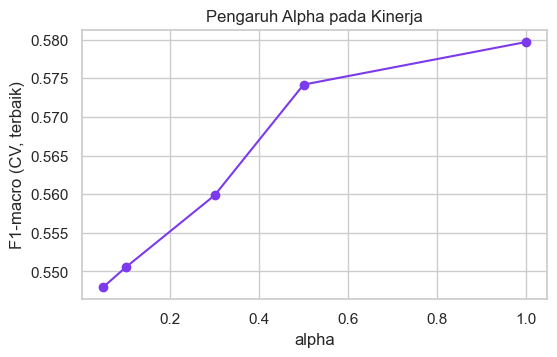

In [18]:
# Pengaruh alpha (Laplace smoothing) terhadap F1-macro
g = hasil_grid.groupby("nb__alpha")["mean_test_score"].max()
plt.figure(figsize=(6, 3.5)); plt.plot(g.index, g.values, marker="o", color="#7C3AED")
plt.xlabel("alpha"); plt.ylabel("F1-macro (CV, terbaik)"); plt.title("Pengaruh Alpha pada Kinerja"); plt.show()

In [19]:
# %% 6.1 TF-IDF, SMOTE, dan Pelatihan Model Final
bp = gs.best_params_
vectorizer = TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"], max_features=bp["tfidf__max_features"],
                             min_df=bp["tfidf__min_df"], sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_txt)      # fit hanya di data latih
X_test = vectorizer.transform(X_test_txt)
print("Bentuk matriks TF-IDF latih:", X_train.shape)

sampler = buat_sampler(y_train)
X_train_bal, y_train_bal = sampler.fit_resample(X_train, y_train)     # SMOTE hanya pada data latih
print(type(sampler).__name__)
pd.DataFrame({"Sebelum": y_train.value_counts(), "Sesudah": pd.Series(y_train_bal).value_counts()})

Bentuk matriks TF-IDF latih: (799, 981)
SMOTE


,Sebelum,Sesudah
label,,
Positif,625,625
Negatif,105,625
Netral,69,625


In [20]:
# %% Pelatihan model final
model = MultinomialNB(alpha=bp["nb__alpha"])
model.fit(X_train_bal, y_train_bal)
classes = list(model.classes_)
print(f"Model Multinomial Naive Bayes dilatih (alpha={bp['nb__alpha']}), kelas: {classes}")

Model Multinomial Naive Bayes dilatih (alpha=1.0), kelas: [np.str_('Negatif'), np.str_('Netral'), np.str_('Positif')]


In [21]:
# %% Evaluasi model
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)
 
metrik = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}
tabel_metrik = pd.DataFrame(metrik, index=["Nilai"]).T
display(tabel_metrik.style.format("{:.4f}").background_gradient(cmap="Purples"))
 
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

,Nilai
Accuracy,0.7350
Precision (macro),0.4563
Recall (macro),0.4949
F1-Score (macro),0.4669
F1-Score (weighted),0.7548



Classification Report:

              precision    recall  f1-score   support

     Negatif       0.38      0.59      0.46        27
      Netral       0.05      0.06      0.06        17
     Positif       0.94      0.83      0.88       156

    accuracy                           0.73       200
   macro avg       0.46      0.49      0.47       200
weighted avg       0.79      0.73      0.75       200



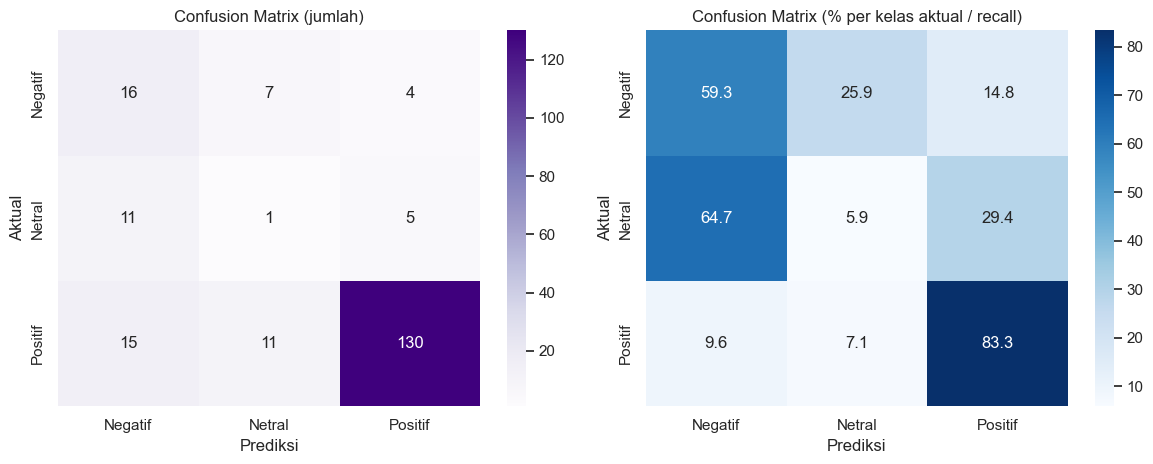

In [22]:
# %% Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
 
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set(title="Confusion Matrix (jumlah)", xlabel="Prediksi", ylabel="Aktual")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set(title="Confusion Matrix (% per kelas aktual / recall)", xlabel="Prediksi", ylabel="Aktual")
plt.tight_layout(); plt.show()

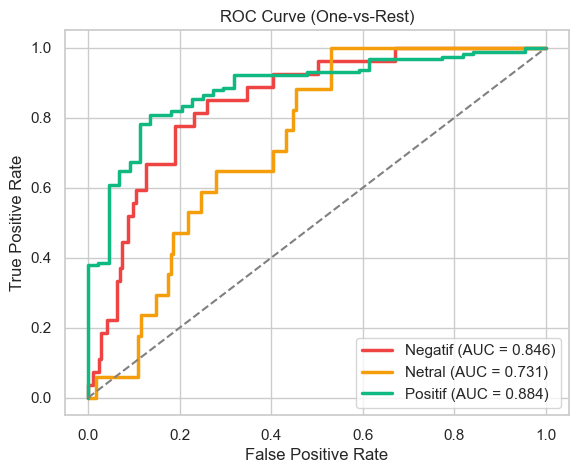

ROC-AUC macro: 0.8203


In [23]:
# ROC Curve One-vs-Rest
Y = label_binarize(y_test, classes=classes)
plt.figure(figsize=(6.5, 5))
aucs = {}
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, i], y_prob[:, i])
    aucs[c] = roc_auc_score(Y[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, lw=2.5, color=PALETTE[c], label=f"{c} (AUC = {aucs[c]:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve (One-vs-Rest)")
plt.legend(loc="lower right"); plt.show()
print(f"ROC-AUC macro: {np.mean(list(aucs.values())):.4f}")

,Fold,Accuracy,F1-macro
0,Fold 1,0.7688,0.5531
1,Fold 2,0.8000,0.5978
2,Fold 3,0.7937,0.6514
3,Fold 4,0.7750,0.5621
4,Fold 5,0.7296,0.5341


Accuracy  : 0.7734 ± 0.0248
F1-macro  : 0.5797 ± 0.0414


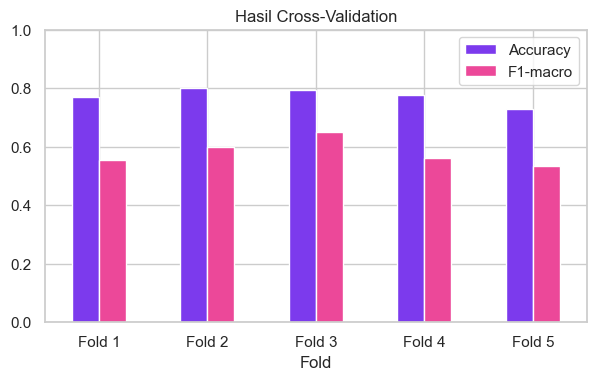

In [24]:
# %% Cross-Validation
# Cross-Validation pada data latih (TF-IDF + SMOTE dihitung ulang di tiap fold)
best_pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"],
                              min_df=bp["tfidf__min_df"], max_features=bp["tfidf__max_features"], sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB(alpha=bp["nb__alpha"])),
])
skf = StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED)
cv_acc = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="accuracy")
cv_f1 = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="f1_macro")
 
cv_df = pd.DataFrame({"Fold": [f"Fold {i+1}" for i in range(N_FOLD)], "Accuracy": cv_acc, "F1-macro": cv_f1})
display(cv_df.style.format({"Accuracy": "{:.4f}", "F1-macro": "{:.4f}"}))
print(f"Accuracy  : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"F1-macro  : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")
 
cv_df.set_index("Fold").plot(kind="bar", figsize=(7, 3.8), color=["#7C3AED", "#EC4899"], rot=0)
plt.ylim(0, 1); plt.title("Hasil Cross-Validation"); plt.show()

In [25]:
# %% Analisis error
# Contoh prediksi yang salah (untuk analisis error)
salah = pd.DataFrame({"ulasan": X_test_txt.values, "aktual": y_test.values, "prediksi": y_pred,
                      "keyakinan": y_prob.max(axis=1)})
salah = salah[salah["aktual"] != salah["prediksi"]].sort_values("keyakinan", ascending=False)
print(f"Jumlah salah prediksi: {len(salah)} dari {len(y_test)}")
salah.head(10)

Jumlah salah prediksi: 53 dari 200


,ulasan,aktual,prediksi,keyakinan
143,turut aplikasi bagus yah lebih suka baca buku ...,Negatif,Positif,0.780012
121,hai benar benar terima kasih sangat bantu paha...,Negatif,Positif,0.774989
67,kendala akhir akhir tiap pakai aplikasi sering...,Netral,Negatif,0.752559
166,seluruh sangat baik sangat bantu ajar utama ba...,Positif,Negatif,0.727218
62,baru coba beberapa hari rasa puas mudah erti b...,Positif,Negatif,0.696299
168,soal aplikasi no problemakan npln sms lain sua...,Positif,Negatif,0.687815
178,sekarang kan gratis engga gratis sepenuh yah t...,Positif,Netral,0.676765
48,kadang masalah kata server sibuk jaring penuh ...,Positif,Netral,0.675897
58,beberapa kali login nomor orang tua namun teta...,Netral,Negatif,0.669019
25,gasuka sinyal jdi buruk lgi muter video langga...,Negatif,Netral,0.639136


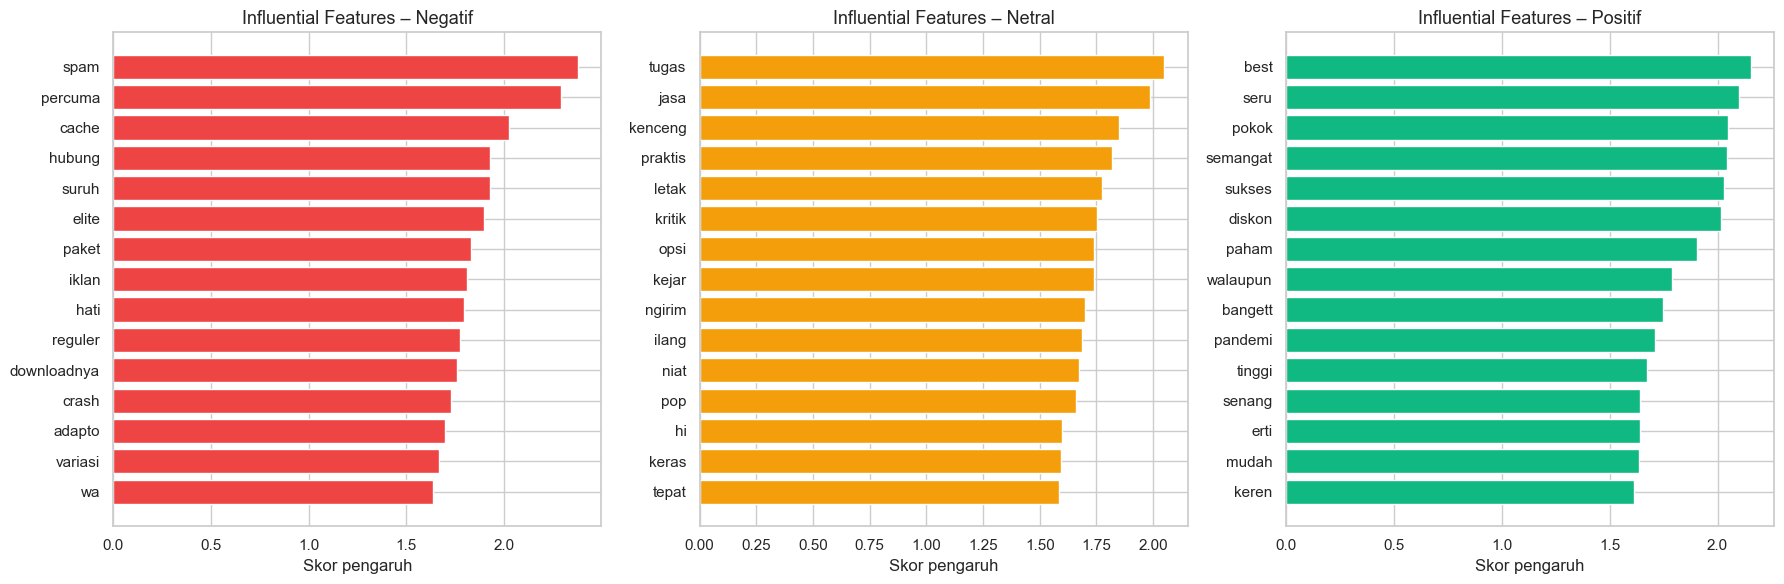

In [26]:
# %% Fitur berpengaruh
fitur = np.array(vectorizer.get_feature_names_out())
flp = model.feature_log_prob_
 
def fitur_berpengaruh(top_n=15):
    rows = []
    for i, c in enumerate(classes):
        selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
        for rank, j in enumerate(np.argsort(selisih)[::-1][:top_n], 1):
            rows.append({"Kelas": c, "Rank": rank, "Fitur": fitur[j], "Skor Pengaruh": selisih[j],
                         "Rasio Odds": np.exp(selisih[j]), "log P(kata|kelas)": flp[i, j]})
    return pd.DataFrame(rows)
 
inf = fitur_berpengaruh(15)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, c in zip(axes, classes):
    d = inf[inf["Kelas"] == c].sort_values("Skor Pengaruh")
    ax.barh(d["Fitur"], d["Skor Pengaruh"], color=PALETTE[c]); ax.set_title(f"Influential Features – {c}", fontsize=13)
    ax.set_xlabel("Skor pengaruh")
plt.tight_layout(); plt.show()

In [27]:
display(inf.pivot(index="Rank", columns="Kelas", values="Fitur") [classes])

Kelas,Negatif,Netral,Positif
Rank,,,
1,spam,tugas,best
2,percuma,jasa,seru
3,cache,kenceng,pokok
4,hubung,praktis,semangat
5,suruh,letak,sukses
6,elite,kritik,diskon
7,paket,opsi,paham
8,iklan,kejar,walaupun
9,hati,ngirim,bangett


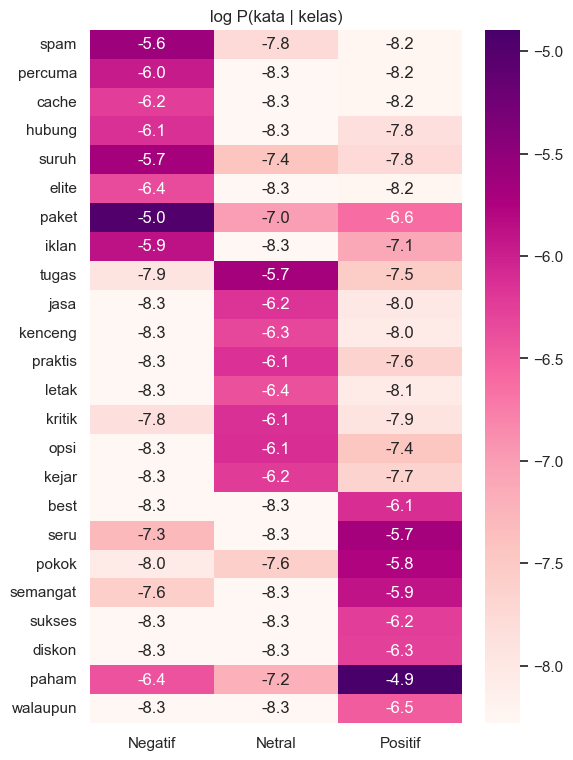

In [28]:
# Heatmap log-probabilitas kata teratas x kelas
pilih = []
for i in range(len(classes)):
    selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
    pilih += list(np.argsort(selisih)[::-1][:8])
pilih = list(dict.fromkeys(pilih))
hm = pd.DataFrame(flp[:, pilih].T, index=fitur[pilih], columns=classes)
plt.figure(figsize=(6, 9)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="RdPu"); plt.title("log P(kata | kelas)"); plt.show()

,Aspek,Jumlah,Rata-rata Rating,% Negatif,% Netral,% Positif
0,Materi & Soal,638,4.35,9.6,7.2,83.2
1,Mentor / Guru,629,4.48,7.0,6.4,86.6
2,Video & Animasi,402,4.25,11.4,9.0,79.6
3,Teknis & Performa,315,3.63,24.8,14.9,60.3
4,Fitur & Tampilan,266,4.23,12.0,7.5,80.5
5,Harga & Langganan,260,3.83,23.8,8.1,68.1
6,Layanan & Iklan,63,2.78,50.8,11.1,38.1


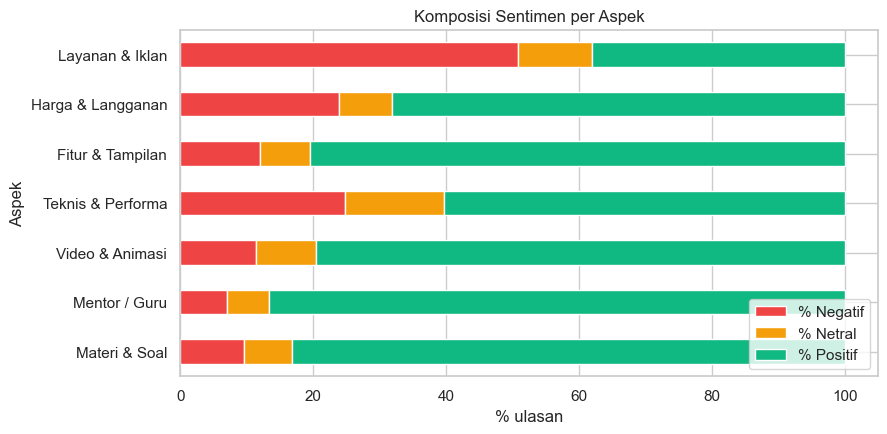

In [29]:
# %% Analisis sentimen per aspek
ASPEK = {
    "Mentor / Guru": r"guru|mentor|pengajar|tutor|kakak|penjelasan|menjelaskan",
    "Materi & Soal": r"materi|soal|latihan|rangkuman|pembahasan|kuis|pelajaran|kurikulum|bab",
    "Video & Animasi": r"video|animasi|tayang|nonton|subtitle|suara",
    "Harga & Langganan": r"harga|mahal|langganan|berlangganan|paket|bayar|biaya|promo|diskon|gratis|saldo|refund",
    "Teknis & Performa": r"error|bug|crash|lemot|lambat|loading|download|kuota|login|update|hang|ngelag|tidak bisa|gak bisa|susah",
    "Fitur & Tampilan": r"fitur|tampilan|menu|interface|desain|navigasi|opsi",
    "Layanan & Iklan": r"spam|iklan|telepon|sales|cs|customer|layanan|notifikasi|tawar",
}
low = df["content"].str.lower()
rows = []
for nama, pola in ASPEK.items():
    m = low.str.contains(pola, regex=True); sub = df[m]
    rows.append({"Aspek": nama, "Jumlah": int(m.sum()), "Rata-rata Rating": sub["score"].mean(),
                 "% Negatif": (sub["label"] == "Negatif").mean()*100, "% Netral": (sub["label"] == "Netral").mean()*100,
                 "% Positif": (sub["label"] == "Positif").mean()*100})
asp = pd.DataFrame(rows).sort_values("Jumlah", ascending=False).reset_index(drop=True)
# CATATAN: ujung baris di bawah terpotong di foto (".background..."); "background_gradient" adalah TEBAKAN
display(asp.style.format({"Rata-rata Rating": "{:.2f}", "% Negatif": "{:.1f}", "% Netral": "{:.1f}", "% Positif": "{:.1f}"}).background_gradient(cmap="Purples", subset=["Jumlah"]))

asp.set_index("Aspek")[["% Negatif", "% Netral", "% Positif"]].plot(
    kind="barh", stacked=True, figsize=(9, 4.5), color=[PALETTE["Negatif"], PALETTE["Netral"], PALETTE["Positif"]])
plt.xlabel("% ulasan"); plt.title("Komposisi Sentimen per Aspek"); plt.legend(loc="lower right"); plt.show()

In [30]:
def prediksi(teks, top_k=6):
    bersih = bersihkan_teks(teks)
    X = vectorizer.transform([bersih])
    p = model.predict_proba(X)[0]
    pred = classes[p.argmax()]
    kontrib = []
    ref = classes[np.argsort(p)[::-1][1]]
    for j in X.nonzero()[1]:
        kontrib.append((fitur[j], (flp[classes.index(pred), j] - flp[classes.index(ref), j]) * X[0, j]))
    kontrib = sorted(kontrib, key=lambda x: -x[1])[:top_k]
    return pred, dict(zip(classes, p.round(3))), kontrib

for t in ["Aplikasinya bagus banget, materi lengkap dan gurunya jelas!",
          "Sering error, tidak bisa login, kecewa sekali",
          "Lumayan lah tapi masih banyak yang perlu diperbaiki"]:
    pred, prob, kontrib = prediksi(t)
    print(f"\n✍️ {t}\n-> {pred} {prob}\n   kata pendorong: {[k for k, _ in kontrib]}")


✍️ Aplikasinya bagus banget, materi lengkap dan gurunya jelas!
-> Positif {np.str_('Negatif'): np.float64(0.064), np.str_('Netral'): np.float64(0.205), np.str_('Positif'): np.float64(0.731)}
   kata pendorong: ['jelas', 'banget', 'guru', 'lengkap', 'materi', 'aplikasi']

✍️ Sering error, tidak bisa login, kecewa sekali
-> Netral {np.str_('Negatif'): np.float64(0.39), np.str_('Netral'): np.float64(0.563), np.str_('Positif'): np.float64(0.047)}
   kata pendorong: ['error', 'login', 'bisa', 'tidak', 'sekali', 'sering']

✍️ Lumayan lah tapi masih banyak yang perlu diperbaiki
-> Netral {np.str_('Negatif'): np.float64(0.214), np.str_('Netral'): np.float64(0.434), np.str_('Positif'): np.float64(0.352)}
   kata pendorong: ['masih', 'baik', 'perlu', 'banyak', 'lumayan']


In [31]:
import joblib
joblib.dump({"vectorizer": vectorizer, "model": model, "classes": classes, "best_params": bp,
            "metrics": metrik, "cm": cm}, "model_nb_sentimen.jotlib")
df.to_csv("data_bersih_berlabel", index=False)
print("Tersimpan: model_nb_sentimen.jotlib, data_bersih_berlabel.csv, stem_cache.json")

Tersimpan: model_nb_sentimen.jotlib, data_bersih_berlabel.csv, stem_cache.json
